# Experiment A — Stage 1 spatial reconstruction and probe-specific bias

**Goal:** explain why Stage 1 has opposite signed residual biases at different probes (e.g., US/160 positive, DS/160 negative). This is a **Stage 1 diagnostic**, not a causal test of Stage 2 false positives.

Uses the **original trained Stage 1 model**, its **run-specific probe coordinates**, the exact 40-step input and 50/150 normalization, and only fully healthy windows. Training `1211_1` versus evaluation `1212_1` is a *descriptive* cross-run comparison (different probe coordinates and hole sizes; not a controlled domain-shift experiment). No retraining.

Outputs go to `results/experiment_A_stage1_spatial/`. Run from project root or `notebooks/`.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# USER CONFIGURATION
EXPERIMENT = "1212_1"          # original validation experiment; 1211_1 was training
WINDOW_SIZE = 40
BATCH_SIZE = 64               # reduce to 16 or 32 if memory constrained
THRESHOLD = 0.5               # NOT the author's optimized validation threshold
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROBE_ORDER = ["UUS", "US", "DS", "DDS"]

# Works whether Jupyter's working directory is project/notebooks or project/.
start = Path.cwd().resolve()
candidates = [start, start.parent]
PROJECT_ROOT = next((p for p in candidates
                     if (p / "data" / "2026-03-04").is_dir() and (p / "models").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find project root from {start}. Expected data/2026-03-04 and models/ "
        "under the working directory or its parent."
    )
DATA_DIR = PROJECT_ROOT / "data" / "2026-03-04"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "results" / "experiment_A_stage1_spatial"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_PATH = MODELS_DIR / "leak_detect_baseline.pt"
RESIDUAL_PATH = MODELS_DIR / "leak_detect_residual.pt"

for path in [BASELINE_PATH] + [DATA_DIR / f"{p}{EXPERIMENT}.csv" for p in PROBE_ORDER]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required file: {path}")
print("Project:", PROJECT_ROOT)
print("Data:", DATA_DIR)
print("Device:", DEVICE)
print("Output:", OUTPUT_DIR)
# Optional: choose frequencies to inspect. None means automatic top-error frequencies.
PLOT_FREQUENCIES = None  # e.g. ["f80", "f100", "f250"]
PLOT_PROBES = PROBE_ORDER
TOP_N_FREQUENCIES = 5
TRANSITION_THRESHOLD = 0.0  # abs(Re[t]-Re[t-1]) > threshold
MAX_LAG = 15  # descriptive cross-correlation; time steps, not seconds


Project: /home/ubuntu/notebooks/Leak_Detection
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04
Device: cpu
Output: /home/ubuntu/notebooks/Leak_Detection/results/experiment_A_stage1_spatial


## 1. Reuse original forward model and run-specific coordinate configuration

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class BaselineSpectralModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        re_feat_dim=16,
        coord_feat_dim=16
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.re_feat_dim = re_feat_dim
        self.coord_feat_dim = coord_feat_dim

        self.re_embed = nn.Sequential(
            nn.Linear(1, re_feat_dim),
            nn.ReLU()
        )

        self.coord_embed = nn.Sequential(
            nn.Linear(2, coord_feat_dim),
            nn.ReLU()
        )

        self.re_lstm = nn.LSTM(
            input_size=re_feat_dim + coord_feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.re_to_spec = nn.Linear(hidden_dim, Freq)

    def forward(self, X_window, Re_window, coords):

        B, W, P, F = X_window.shape
        assert F == self.Freq

        # Build per-probe inputs in batched form
        re_p = Re_window.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, P, 1)   # (B,W,P,1)
        coord_p = coords.unsqueeze(1).expand(-1, W, -1, -1)                  # (B,W,P,2)

        re_feat = self.re_embed(re_p)                                         # (B,W,P,Cr)
        coord_feat = self.coord_embed(coord_p)                                # (B,W,P,Cc)

        probe_in = torch.cat([re_feat, coord_feat], dim=-1)                   # (B,W,P,Cr+Cc)

        # Move P into batch: (B,W,P,D) -> (B*P,W,D)
        D = probe_in.shape[-1]
        probe_in = probe_in.permute(0, 2, 1, 3).contiguous()                  # (B,P,W,D)
        probe_in = probe_in.view(B * P, W, D)                                 # (B*P,W,D)

        # Shared LSTM over each probe independently
        probe_feats, _ = self.re_lstm(probe_in)                               # (B*P,W,H)

        # Reshape back: (B*P,W,H) -> (B,W,P,H)
        H = probe_feats.shape[-1]
        probe_feats = probe_feats.view(B, P, W, H)                            # (B,P,W,H)
        probe_feats = probe_feats.permute(0, 2, 1, 3).contiguous()            # (B,W,P,H)

        X_hat = self.re_to_spec(probe_feats)                                  # (B,W,P,F)

        return {"baseline": X_hat}

In [4]:
PROBE_COORDS = {
    "1212_1": {
        "UUS": [-4.1275, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [3.0226, 0.0250],
    },
}
HOLE_SIZES = {"1212_1": 4.0, "1211_1": 2.0}


def read_sensor_csv(path):
    df = pd.read_csv(path, low_memory=False)
    if len(df.columns) == 1:
        raise ValueError(f"Only one column found in {path.name}; check CSV delimiter/format.")
    df.columns = [str(c).strip() for c in df.columns]
    return df


def load_experiment(experiment):
    if experiment not in PROBE_COORDS:
        raise ValueError(f"Coordinates not configured for experiment {experiment}")
    dfs = {p: read_sensor_csv(DATA_DIR / f"{p}{experiment}.csv") for p in PROBE_ORDER}

    # Match the original frequency extraction: e.g. '...ǀf1000' -> 'f1000'.
    def frequency_map(df):
        result = {}
        for col in df.columns:
            if "ǀf" in col:
                label = col.split("ǀ")[1]
                if re.fullmatch(r"f[0-9]+(?:_[0-9]+)?", label):
                    result[label] = col
        return result

    freq_maps = {p: frequency_map(df) for p, df in dfs.items()}
    common_freqs = sorted(set.intersection(*(set(m) for m in freq_maps.values())),
                          key=lambda s: float(s[1:].replace("_", ".")))
    if len(common_freqs) != 27:
        raise ValueError(f"Expected 27 common frequencies; found {len(common_freqs)}: {common_freqs}")

    # Original notebook picks a reference dataframe from the grouped probe list.
    # Here use UUS explicitly and check alignment across all probes.
    ref = dfs["UUS"]
    time_col = "Date-Time"
    leak_col = "Leak Event"
    if time_col not in ref or leak_col not in ref:
        raise KeyError(f"Expected columns {time_col!r}, {leak_col!r} in UUS file; got {list(ref.columns)}")
    re_col = next((c for c in ref.columns if "Re" in c or "re" in c), None)
    if re_col is None:
        raise KeyError("No Reynolds-number column found (original notebook searches for 'Re' or 're').")

    min_T = min(len(df) for df in dfs.values())
    if len(set(len(df) for df in dfs.values())) != 1:
        print("WARNING: Unequal sensor lengths; truncating all to", min_T, "(original notebook behavior).")
    time = pd.to_datetime(ref[time_col].iloc[:min_T], errors="raise")
    if time.isna().any():
        raise ValueError("Missing timestamps in reference file")
    for p in PROBE_ORDER[1:]:
        other_time = pd.to_datetime(dfs[p][time_col].iloc[:min_T], errors="raise")
        if not np.array_equal(time.to_numpy(), other_time.to_numpy()):
            raise ValueError(f"Timestamps are not aligned between UUS and {p}. Do not infer on misaligned sensors.")
        if leak_col in dfs[p]:
            a = pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            b = pd.to_numeric(dfs[p][leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            if not np.array_equal(a, b):
                raise ValueError(f"Leak Event labels disagree between UUS and {p}")

    values = []
    for p in PROBE_ORDER:
        columns = [freq_maps[p][f] for f in common_freqs]
        x = dfs[p][columns].iloc[:min_T].apply(pd.to_numeric, errors="coerce").fillna(0.0)
        values.append(x.to_numpy(dtype=np.float32))
    X_raw = np.stack(values, axis=1)     # (T, 4, 27)
    re_raw = pd.to_numeric(ref[re_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy(dtype=np.float32)
    leak = (pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0).astype(np.float32)
    coords = np.array([PROBE_COORDS[experiment][p] for p in PROBE_ORDER], dtype=np.float32)

    return {
        "iteration": experiment,
        "X": torch.from_numpy(X_raw / 50.0),  # exact original normalization
        "Re": torch.from_numpy(re_raw / 150.0),
        "coords": torch.from_numpy(coords),
        "leak_open": leak,
        "datetime": time.to_numpy(),
        "frequency_labels": common_freqs,
        "re_column": re_col,
        "raw_rows": min_T,
    }



In [5]:
# State dictionaries saved by torch.save(model.state_dict(), path), as in the original notebook.
# weights_only=True is preferred for security (PyTorch >=2.0); fall back for older versions.
def load_weights(path):
    try:
        obj = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        obj = torch.load(path, map_location="cpu")
    if not isinstance(obj, dict):
        raise TypeError(f"{path.name} is not a state dictionary")
    if "state_dict" in obj and isinstance(obj["state_dict"], dict):
        obj = obj["state_dict"]
    return obj

baseline_model = BaselineSpectralModel(Freq=27, hidden_dim=64, re_feat_dim=16, coord_feat_dim=16)
baseline_model.load_state_dict(load_weights(BASELINE_PATH), strict=True)
baseline_model = baseline_model.to(DEVICE).eval()
print("Loaded Stage 1:", BASELINE_PATH.name)


Loaded Stage 1: leak_detect_baseline.pt


In [6]:
@torch.inference_mode()
def stage1_healthy_endpoints(sample, window_size=40, batch_size=64):
    X, Re = sample["X"], sample["Re"]
    Xw_all = X.unfold(0, window_size, 1).permute(0, 3, 1, 2).contiguous()
    Rew_all = Re.unfold(0, window_size, 1)
    healthy_window = np.convolve((sample["leak_open"] == 0).astype(int),
                                 np.ones(window_size, dtype=int), mode="valid") == window_size
    selected = np.flatnonzero(healthy_window)
    if len(selected) == 0:
        raise ValueError("No fully healthy 40-step windows found")
    coords = sample["coords"].unsqueeze(0).to(DEVICE)
    pred_list, actual_list = [], []
    for start in range(0, len(selected), batch_size):
        ix = selected[start:start + batch_size]
        xw = Xw_all[ix].to(DEVICE)
        rew = Rew_all[ix].to(DEVICE)
        baseline = baseline_model(xw, rew, coords.expand(len(ix), -1, -1))["baseline"]
        # (B, 4, 27): only endpoint, not every overlapping window position
        pred_list.append((baseline[:, -1] * 50).cpu().numpy())
        actual_list.append((xw[:, -1] * 50).cpu().numpy())
    actual = np.concatenate(actual_list)
    predicted = np.concatenate(pred_list)
    endpoint_idx = selected + window_size - 1
    re_all = sample["Re"].numpy() * 150
    df = pd.DataFrame({
        "observation_index": endpoint_idx + 1,
        "datetime": pd.to_datetime(sample["datetime"][endpoint_idx]),
        "Reynolds": re_all[endpoint_idx],
        "delta_Reynolds": np.r_[0, np.diff(re_all)][endpoint_idx],
        "abs_delta_Reynolds": np.abs(np.r_[0, np.diff(re_all)][endpoint_idx]),
        "endpoint_RMSE": np.sqrt(np.mean((actual - predicted)**2, axis=(1, 2))),
        "endpoint_MAE": np.mean(np.abs(actual - predicted), axis=(1, 2)),
        "actual_spectrum_RMS": np.sqrt(np.mean(actual**2, axis=(1, 2))),
    })
    df["relative_RMSE"] = df.endpoint_RMSE / df.actual_spectrum_RMS.replace(0, np.nan)
    df["is_transition"] = df.abs_delta_Reynolds > TRANSITION_THRESHOLD
    return df, actual, predicted, selected



## 2. Validate timestamp and Reynolds alignment across all four probes, for both runs

Do **not** assume identical Reynolds simply because CSVs contain the same column name. Fail on mismatched timestamps; report Reynolds mismatches, NaNs, and leak-label discrepancies.

In [7]:
RUNS = ["1211_1", "1212_1"]
FREQUENCIES_OF_INTEREST = ["f50", "f80", "f160", "f250"]

def check_raw_alignment(run):
    frames = {p: read_sensor_csv(DATA_DIR / f"{p}{run}.csv") for p in PROBE_ORDER}
    rows = []
    ref = frames["UUS"]
    rcol = next(c for c in ref if "reynolds" in c.lower())
    ref_re = pd.to_numeric(ref[rcol], errors="coerce").to_numpy()
    ref_time = pd.to_datetime(ref["Date-Time"], errors="raise").to_numpy()
    for p, df in frames.items():
        c = next(c for c in df if "reynolds" in c.lower())
        re = pd.to_numeric(df[c], errors="coerce").to_numpy()
        tm = pd.to_datetime(df["Date-Time"], errors="raise").to_numpy()
        if len(tm) != len(ref_time) or not np.array_equal(tm, ref_time):
            raise ValueError(f"{run}/{p}: timestamp or row count mismatch; do not align by row position")
        diff = np.abs(re - ref_re)
        valid = np.isfinite(diff)
        rows.append(dict(run=run, probe=p, rows=len(re), missing_Re=int((~valid).sum()),
                         mismatches_gt_1e_6=int(np.sum(valid & (diff > 1e-6))),
                         max_abs_difference=float(np.max(diff[valid])) if valid.any() else np.nan))
    return pd.DataFrame(rows)

alignment = pd.concat([check_raw_alignment(r) for r in RUNS], ignore_index=True)
display(alignment)
alignment.to_csv(OUTPUT_DIR / "reynolds_alignment.csv", index=False)
if alignment.missing_Re.any() or alignment.mismatches_gt_1e_6.any():
    raise ValueError("Reynolds is not fully identical across probes. Investigate before interpreting the model.")

,run,probe,rows,missing_Re,mismatches_gt_1e_6,max_abs_difference
0,1211_1,UUS,10801,0,0,0.0
1,1211_1,US,10801,0,0,0.0
2,1211_1,DS,10801,0,0,0.0
3,1211_1,DDS,10801,0,0,0.0
4,1212_1,UUS,10801,0,0,0.0
5,1212_1,US,10801,0,0,0.0
6,1212_1,DS,10801,0,0,0.0
7,1212_1,DDS,10801,0,0,0.0


## 3. Stage 1 inference on both runs (fully healthy 40-step windows only)

In [8]:
results = {}
for run in RUNS:
    s = load_experiment(run)
    df, y, yhat, selected = stage1_healthy_endpoints(s, WINDOW_SIZE, BATCH_SIZE)
    if not np.isfinite(y).all() or not np.isfinite(yhat).all():
        raise ValueError(f"Non-finite spectra in {run}")
    results[run] = dict(sample=s, tracking=df, actual=y, predicted=yhat, residual=y-yhat)
    print(run, 'healthy endpoints', len(df), 'RMSE', round(float(np.sqrt(np.mean((y-yhat)**2))), 4))

1211_1 healthy endpoints 7567 RMSE 3.6347
1212_1 healthy endpoints 7567 RMSE 2.4713


## 4. Compare probe × frequency RMSE and signed bias across runs

Residual = **actual − predicted**. Positive = underprediction; negative = overprediction. RMSE has no sign. Aggregate metrics are computed over aligned healthy endpoints, not independent observations.

RMSE        signed_bias       
run   1211_1 1212_1      1211_1 1212_1
probe                                 
DDS    3.275  3.161      -0.070 -0.169
DS     4.739  2.641       2.437 -1.447
US     4.275  5.227      -2.546  2.406
UUS    2.194  2.255      -0.010  0.023

RMSE        signed_bias       
run   1211_1 1212_1      1211_1 1212_1
probe                                 
DDS    2.267  2.724      -0.004 -0.319
DS     4.872  2.490       3.816 -0.357
US     4.208  6.718      -3.383  5.824
UUS    2.248  2.385      -0.076  0.006

RMSE        signed_bias       
run   1211_1 1212_1      1211_1 1212_1
probe                                 
DDS    2.177  2.414      -0.148 -0.345
DS     4.568  3.650       3.358 -2.504
US     5.005  2.936      -3.921  0.800
UUS    1.857  1.943      -0.201 -0.204

RMSE        signed_bias       
run   1211_1 1212_1      1211_1 1212_1
probe                                 
DDS    2.411  2.247      -0.012  0.429
DS     2.509  9.299      -0.364 -8.919
US     8.110  1.613       7.349 -0.352
UUS    3.304  2.529       0.252  1.014

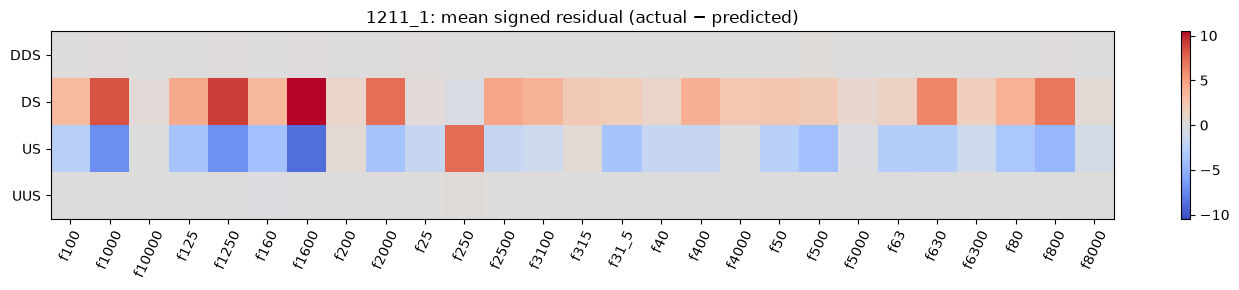

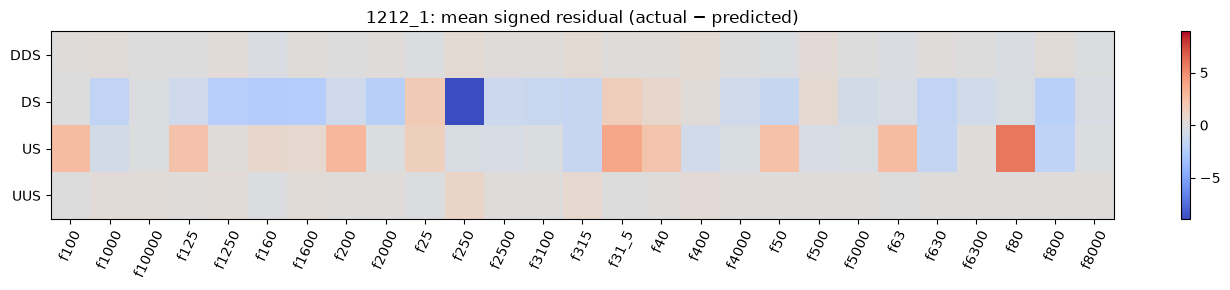

In [9]:
rows=[]
for run, obj in results.items():
    for pi,p in enumerate(PROBE_ORDER):
        for fi,f in enumerate(obj['sample']['frequency_labels']):
            e=obj['residual'][:,pi,fi]
            rows.append(dict(run=run,probe=p,frequency=f,RMSE=float(np.sqrt(np.mean(e**2))),
                             MAE=float(np.mean(np.abs(e))),signed_bias=float(np.mean(e)),
                             residual_std=float(np.std(e)),n_endpoints=len(e)))
metrics=pd.DataFrame(rows)
metrics.to_csv(OUTPUT_DIR/'probe_frequency_metrics.csv',index=False)
for f in FREQUENCIES_OF_INTEREST:
    display(metrics[metrics.frequency.eq(f)].pivot(index='probe',columns='run',values=['RMSE','signed_bias']).round(3))
for run in RUNS:
    m=metrics[metrics.run.eq(run)].pivot(index='probe',columns='frequency',values='signed_bias')
    fig,ax=plt.subplots(figsize=(14,3)); im=ax.imshow(m.values,aspect='auto',cmap='coolwarm',vmin=-np.nanmax(abs(m.values)),vmax=np.nanmax(abs(m.values)))
    ax.set_xticks(range(len(m.columns)),m.columns,rotation=65);ax.set_yticks(range(4),m.index);ax.set_title(f'{run}: mean signed residual (actual − predicted)');fig.colorbar(im,ax=ax)
    fig.tight_layout();fig.savefig(OUTPUT_DIR/f'{run}_signed_bias_heatmap.png',dpi=160);plt.show()

## 5. Does the model reproduce spatial differences?

For each frequency, compare measured versus predicted **US − DS**. If the contrast is wrong, the model has not reconstructed the spatial relationship, regardless of aggregate RMSE.

In [10]:
contrast_rows=[]
for run,obj in results.items():
    freqs=obj['sample']['frequency_labels']
    for f in FREQUENCIES_OF_INTEREST:
        j=freqs.index(f)
        act=obj['actual'][:,1,j]-obj['actual'][:,2,j]
        pred=obj['predicted'][:,1,j]-obj['predicted'][:,2,j]
        e=act-pred
        contrast_rows.append(dict(run=run,frequency=f,measured_mean=float(act.mean()),predicted_mean=float(pred.mean()),
                                  contrast_bias=float(e.mean()),contrast_RMSE=float(np.sqrt(np.mean(e**2))),
                                  n=len(e)))
contrast=pd.DataFrame(contrast_rows)
display(contrast.round(3));contrast.to_csv(OUTPUT_DIR/'US_minus_DS_contrast.csv',index=False)

,run,frequency,measured_mean,predicted_mean,contrast_bias,contrast_RMSE,n
0,1211_1,f50,-3.490,1.493,-4.983,8.126,7567
1,1211_1,f80,-5.969,1.230,-7.199,7.921,7567
2,1211_1,f160,-7.820,-0.540,-7.279,8.046,7567
3,1211_1,f250,6.840,-0.874,7.713,8.046,7567
4,1212_1,f50,5.347,1.494,3.853,6.761,7567
5,1212_1,f80,7.412,1.230,6.182,7.347,7567
6,1212_1,f160,2.763,-0.541,3.303,4.241,7567
7,1212_1,f250,7.696,-0.870,8.567,8.823,7567


## 6. Actual versus predicted amplitude by Reynolds (train and evaluation)

Bin by Reynolds to reduce clutter; display within-bin means and counts. Differences can reflect model fit, probe coordinates, run conditions, and other confounding—not automatically a domain shift.

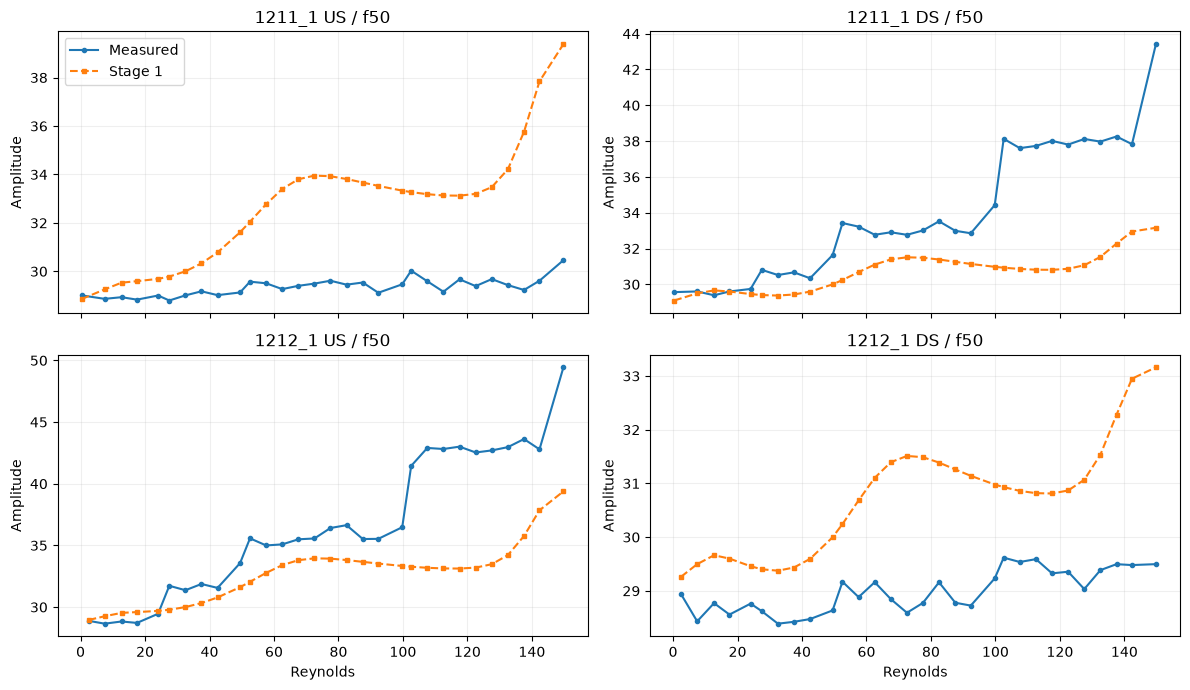

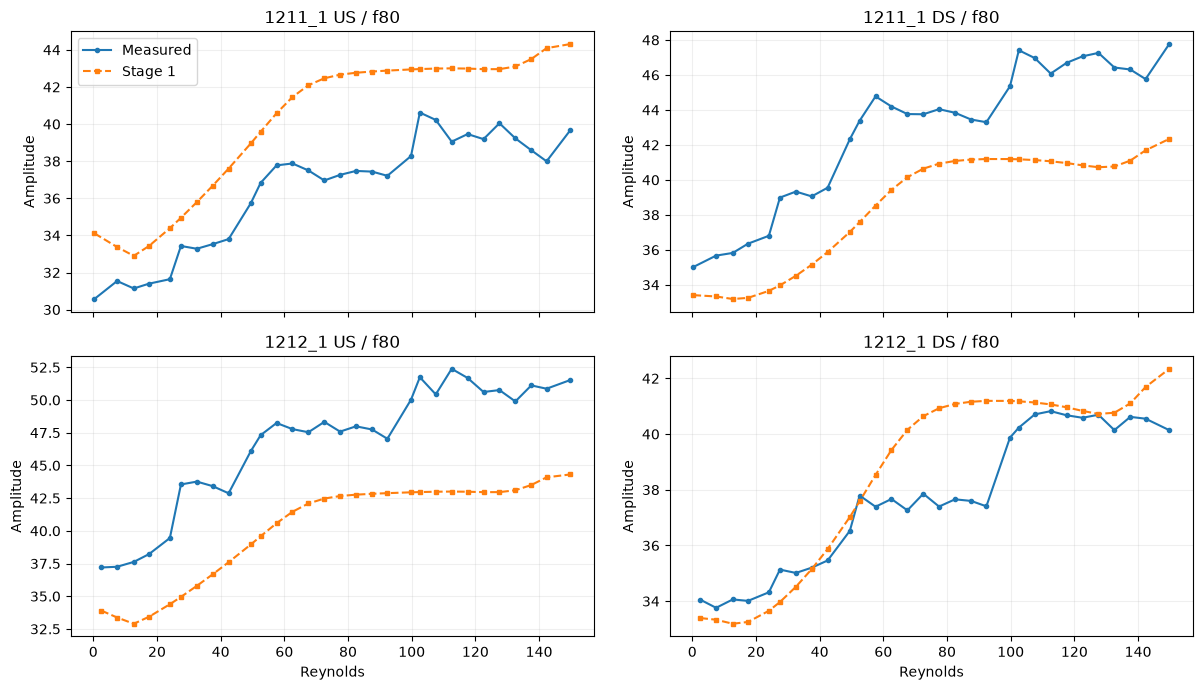

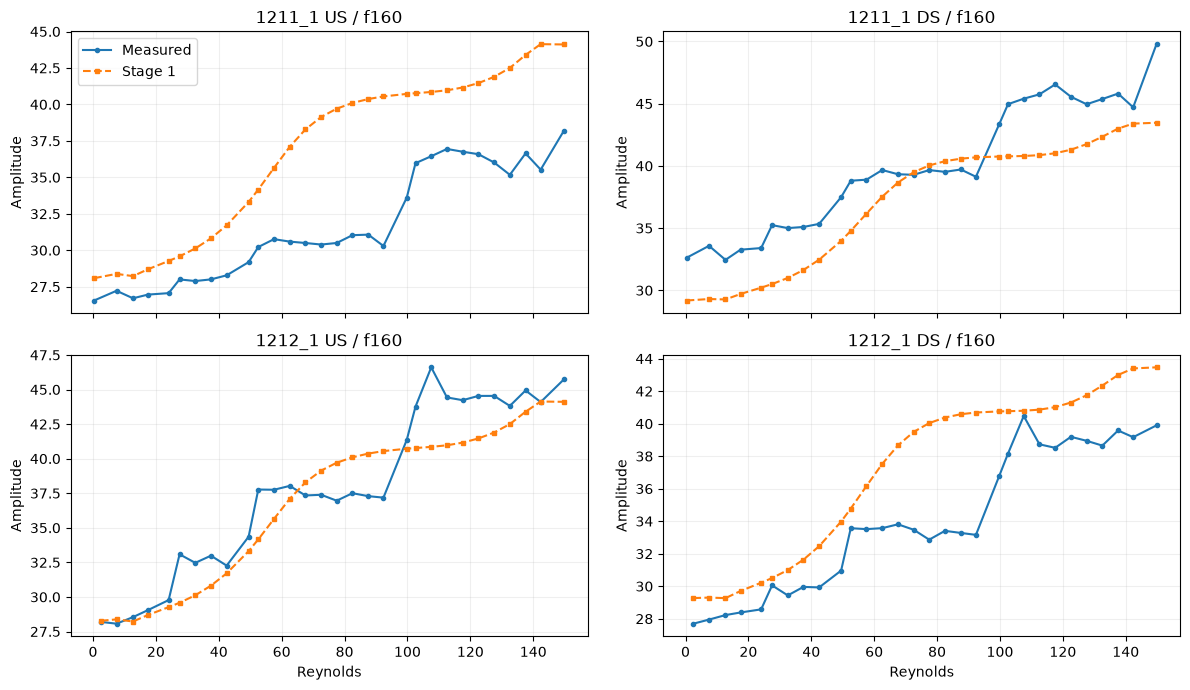

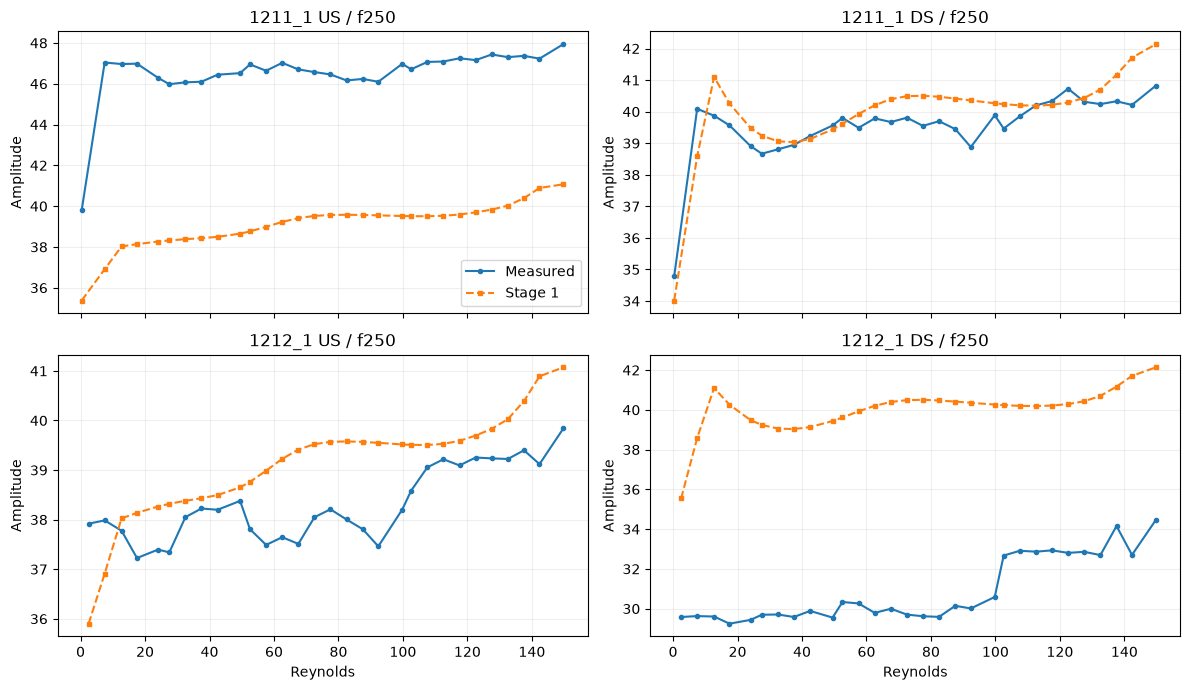

In [11]:
bin_edges=np.arange(0,165,5)
for f in FREQUENCIES_OF_INTEREST:
    fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
    for ri,run in enumerate(RUNS):
        obj=results[run]; re=obj['tracking'].Reynolds.to_numpy();j=obj['sample']['frequency_labels'].index(f)
        for ci,p in enumerate(['US','DS']):
            k=PROBE_ORDER.index(p);ax=axes[ri,ci]
            z=pd.DataFrame({'re':re,'actual':obj['actual'][:,k,j],'predicted':obj['predicted'][:,k,j]})
            z['bin']=pd.cut(z.re,bin_edges)
            g=z.groupby('bin',observed=True).agg(re=('re','mean'),actual=('actual','mean'),predicted=('predicted','mean'),n=('re','size'))
            g=g[g.n>=10]
            ax.plot(g.re,g.actual,'o-',label='Measured',ms=3)
            ax.plot(g.re,g.predicted,'s--',label='Stage 1',ms=3)
            ax.set_title(f'{run} {p} / {f}');ax.set_ylabel('Amplitude');ax.grid(alpha=.2)
            if ri==1:ax.set_xlabel('Reynolds')
            if ri==0 and ci==0:ax.legend()
    fig.tight_layout();fig.savefig(OUTPUT_DIR/f'{f}_actual_vs_predicted_by_Re.png',dpi=160);plt.show()

## 7. Check if signed errors change with Reynolds and time

Plot US and DS residuals at 160 Hz and the spatial contrast residual over the healthy run. A time trend is descriptive; Reynolds and time can be correlated.

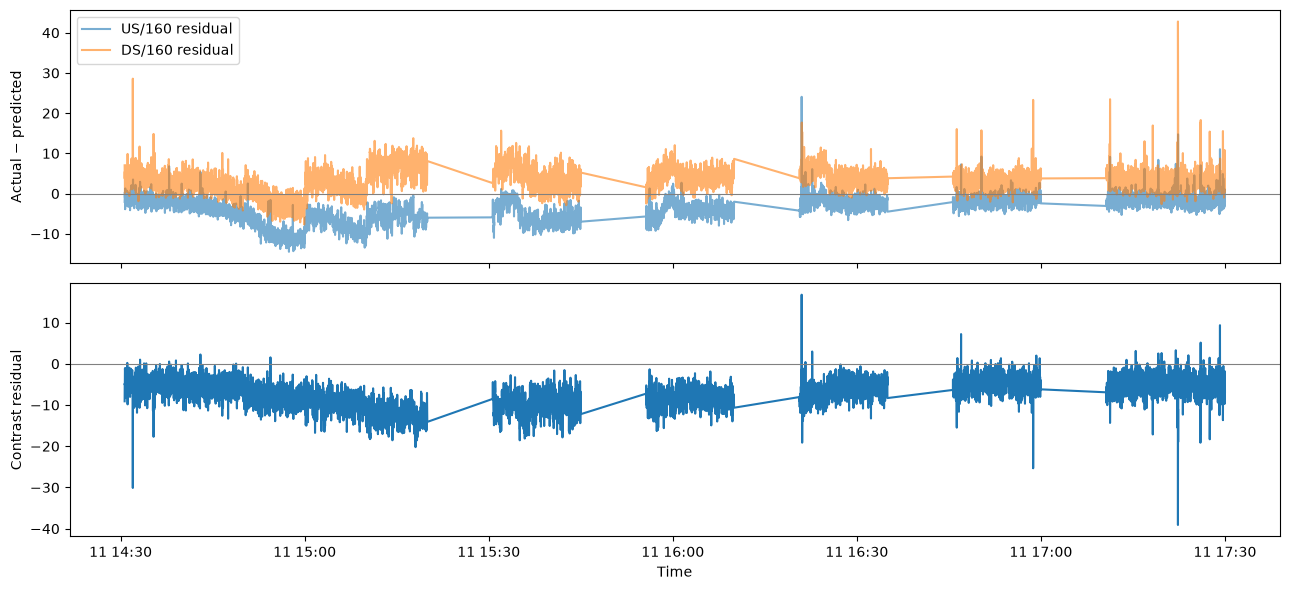

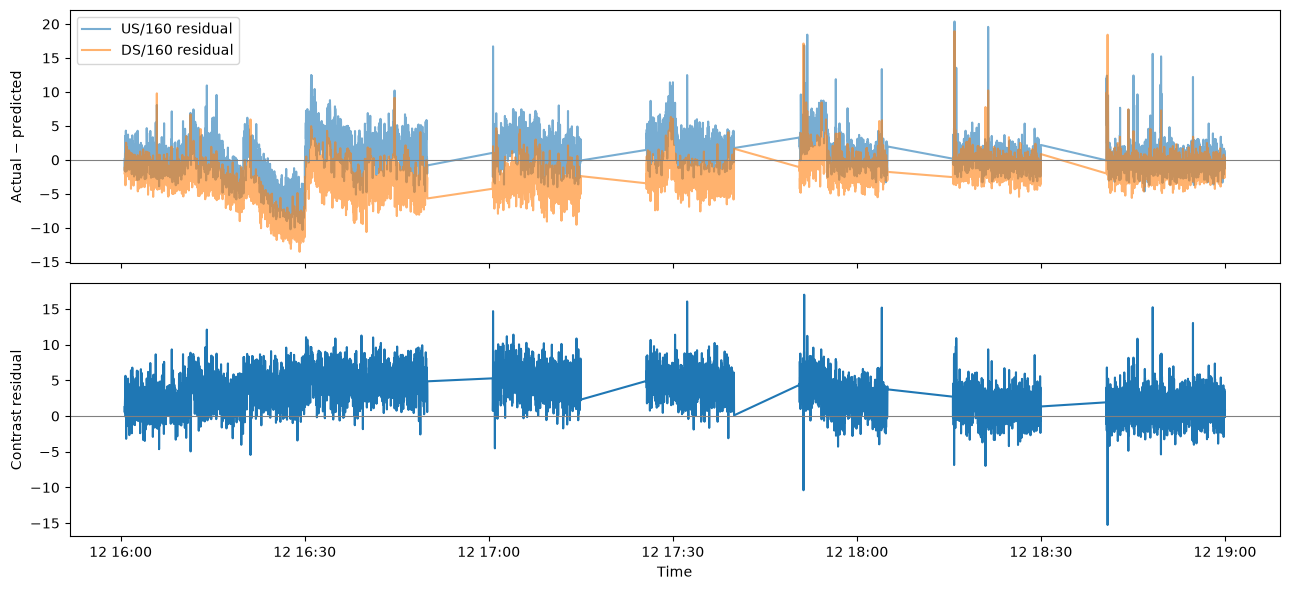

In [12]:
for run,obj in results.items():
    j=obj['sample']['frequency_labels'].index('f160')
    df=obj['tracking'];t=df.datetime
    eu=obj['residual'][:,1,j];ed=obj['residual'][:,2,j]
    fig,axs=plt.subplots(2,1,figsize=(13,6),sharex=True)
    axs[0].plot(t,eu,label='US/160 residual',alpha=.6);axs[0].plot(t,ed,label='DS/160 residual',alpha=.6)
    axs[0].axhline(0,color='gray',lw=.8);axs[0].legend();axs[0].set_ylabel('Actual − predicted')
    axs[1].plot(t,eu-ed,label='US − DS contrast error');axs[1].axhline(0,color='gray',lw=.8)
    axs[1].set_ylabel('Contrast residual');axs[1].set_xlabel('Time');fig.tight_layout()
    fig.savefig(OUTPUT_DIR/f'{run}_160Hz_residual_over_time.png',dpi=160);plt.show()

## Interpretation and decision

1. If alignment fails, fix preprocessing before interpreting results.
2. If the US−DS contrast is biased even on training-run healthy data, investigate Stage 1 fit, output scaling, coordinates, and channel ordering.
3. If it is substantially worse on evaluation, investigate run-specific geometry/conditions and generalization.
4. **Do not infer Stage 2 false-positive causation from these plots.** That requires direct Stage 2 interventions.

**Limitations:** training-run inference is in-sample; overlapping windows are autocorrelated; training and validation have different probe coordinates/hole sizes; healthy-only filtering depends on Leak Event labels.

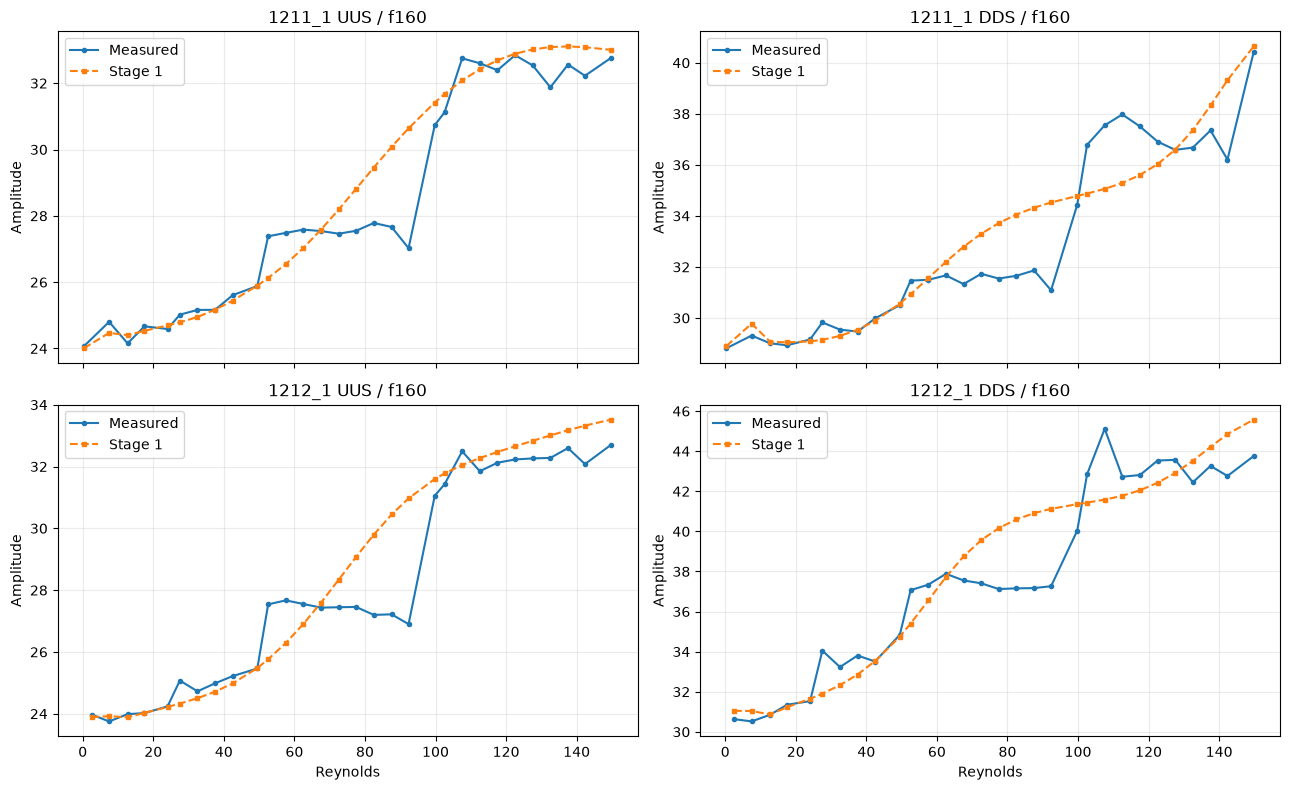

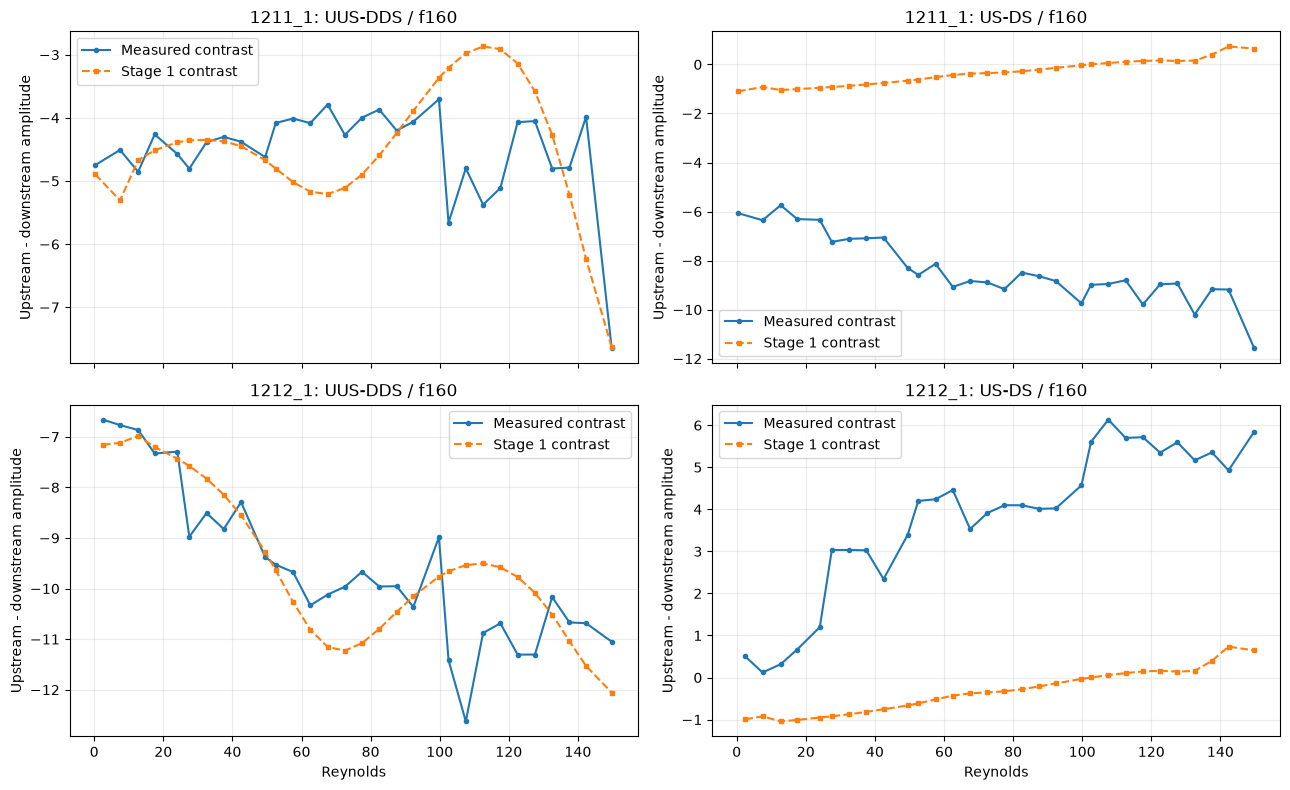

In [14]:

# Experiment A: 160 Hz — UUS/DDS and spatial contrast comparison
# Requires Section 3 to have been executed (results dictionary).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert "results" in globals(), "Run Experiment A Section 3 first."

RUNS = ["1211_1", "1212_1"]
FREQ = "f160"
BIN_EDGES = np.arange(0, 165, 5)

def binned_by_re(run, series):
    re = results[run]["tracking"]["Reynolds"].to_numpy()
    df = pd.DataFrame({"Re": re, "value": series})
    df["bin"] = pd.cut(df["Re"], BIN_EDGES)

    grouped = df.groupby("bin", observed=True).agg(
        Re=("Re", "mean"),
        value=("value", "mean"),
        n=("value", "size")
    )
    return grouped[grouped["n"] >= 10]

def get_channel(run, probe, kind):
    obj = results[run]
    pi = PROBE_ORDER.index(probe)
    fi = obj["sample"]["frequency_labels"].index(FREQ)
    return obj[kind][:, pi, fi]

# FIGURE 1: UUS and DDS — measured versus predicted
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for row, run in enumerate(RUNS):
    for col, probe in enumerate(["UUS", "DDS"]):
        ax = axes[row, col]

        for kind, label, style in [
            ("actual", "Measured", "o-"),
            ("predicted", "Stage 1", "s--")
        ]:
            g = binned_by_re(run, get_channel(run, probe, kind))
            ax.plot(g["Re"], g["value"], style,
                    label=label, markersize=3)

        ax.set_title(f"{run} {probe} / {FREQ}")
        ax.set_ylabel("Amplitude")
        ax.grid(alpha=0.25)
        ax.legend()

        if row == 1:
            ax.set_xlabel("Reynolds")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "f160_UUS_DDS_actual_vs_predicted_by_Re.png",
    dpi=160
)
plt.show()

# FIGURE 2: UUS-DDS versus US-DS spatial contrast
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

PAIRS = [("UUS", "DDS"), ("US", "DS")]

for row, run in enumerate(RUNS):
    for col, (upstream, downstream) in enumerate(PAIRS):
        ax = axes[row, col]

        for kind, label, style in [
            ("actual", "Measured contrast", "o-"),
            ("predicted", "Stage 1 contrast", "s--")
        ]:
            contrast = (
                get_channel(run, upstream, kind)
                - get_channel(run, downstream, kind)
            )
            g = binned_by_re(run, contrast)

            ax.plot(g["Re"], g["value"], style,
                    label=label, markersize=3)

        ax.set_title(f"{run}: {upstream}-{downstream} / {FREQ}")
        ax.set_ylabel("Upstream - downstream amplitude")
        ax.grid(alpha=0.25)
        ax.legend()

        if row == 1:
            ax.set_xlabel("Reynolds")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "f160_UUS_DDS_vs_US_DS_contrast_by_Re.png",
    dpi=160
)
plt.show()
